In [39]:
from typing import TypedDict, Annotated, Literal, Optional
import operator, uuid, json
from pydantic import BaseModel, Field

from langgraph.graph import StateGraph, START, END
from langgraph.types import interrupt, Command
from langgraph.checkpoint.postgres.aio import AsyncPostgresSaver   # nodes are async, so the graph runs via .ainvoke

import psycopg
from psycopg.rows import dict_row
from langchain_groq import ChatGroq
from langchain_openai import ChatOpenAI
import os
from langchain_mcp_adapters.client import MultiServerMCPClient
from dotenv import load_dotenv

import mcp.client.stdio as mcp_stdio
from composio import Composio
import asyncio
import sys
from pathlib import Path
load_dotenv()
from IPython.display import Image,display

from typing import TypedDict, Literal, Annotated
import operator

In [40]:
if not os.getenv("COMPOSIO_API_KEY"):
    raise ValueError("COMPOSIO_API_KEY is not set")
if not os.getenv("COMPOSIO_USER_ID"):
    raise ValueError("COMPOSIO_USER_ID is not set")

composio = Composio(api_key=os.getenv("COMPOSIO_API_KEY"))

WEATHER_API_KEY = os.getenv("OPENWEATHER_API_KEY")
if WEATHER_API_KEY:
    print("True")
    
KLAVIS_GMAIL_MCP_URL = os.environ["KLAVIS_GMAIL_MCP_URL"]
KLAVIS__SLACK_MCP_URL = os.environ["KLAVIS_SLACK_MCP_URL"]
KLAVIS_MCP_TOKEN = os.environ["KLAVIS_MCP_TOKEN"]

True


In [41]:
mcp_stdio.stdio_client.__wrapped__.__defaults__ = (open(os.devnull, "w"),)

In [42]:
from composio import Composio
session = composio.create(
    user_id=os.getenv("COMPOSIO_USER_ID"),
    toolkits=['calendly']
)

url = session.mcp.url

In [43]:
WEATHER_MCP_SERVER = (Path.cwd().parent / "agents" / "mcp_servers" / "weather_server.py").resolve()
assert WEATHER_MCP_SERVER.exists(), f"missing {WEATHER_MCP_SERVER}"


client = MultiServerMCPClient(
    {
        "openweather": {
            "transport": "stdio",
            "command": sys.executable,
            "args": [str(WEATHER_MCP_SERVER)],
            "env": {
                "OPENWEATHER_API_KEY": WEATHER_API_KEY
            },
        },
        "Klavis-strata": {
            "url": KLAVIS_GMAIL_MCP_URL,
            "transport": "streamable_http",
            "headers": {
                "Authorization": f"Bearer {KLAVIS_MCP_TOKEN}"
            }
        },
        "calendly-agent":{
            "transport":"streamable_http",
            "url":session.mcp.url,
            "headers":{
                "x-api-key":os.getenv("COMPOSEIO_API_KEY")
            }
        },
        "Slack-mcp":{
            "url": KLAVIS__SLACK_MCP_URL,
            "transport":"streamable_http",
            "headers":{
                "Authorization":f"Bearer {KLAVIS_MCP_TOKEN}"
            }
        },
    }
)

In [44]:
tools = client.get_tools()
tools = await tools  # resolve coroutine returned by client.get_tools()
print(f"Loaded {len(tools)} MCP tools:")
for t in tools:
    print(f"- {t.name}")
tools

Loaded 30 MCP tools:
- get_current_weather
- gmail_send_email
- gmail_draft_email
- gmail_read_email
- gmail_search_emails
- gmail_modify_email
- gmail_delete_email
- gmail_batch_modify_emails
- gmail_batch_delete_emails
- gmail_get_email_attachments
- gmail_search_contacts
- COMPOSIO_GET_TOOL_SCHEMAS
- COMPOSIO_MANAGE_CONNECTIONS
- COMPOSIO_MULTI_EXECUTE_TOOL
- COMPOSIO_REMOTE_BASH_TOOL
- COMPOSIO_REMOTE_WORKBENCH
- COMPOSIO_SEARCH_TOOLS
- slack_user_list_channels
- slack_get_channel_history
- slack_get_thread_replies
- slack_invite_users_to_channel
- slack_list_users
- slack_user_get_info
- slack_user_search_messages
- slack_user_post_message
- slack_user_reply_to_thread
- slack_user_add_reaction
- slack_bot_post_message
- slack_bot_reply_to_thread
- slack_bot_add_reaction


[StructuredTool(name='get_current_weather', description='Get current weather for a city name or zip/postal code via OpenWeather.\n\n    location: a city name (e.g. "Lahore", "Paris,FR") or a zip/postal code (e.g. "10001")\n    units: "standard" (Kelvin), "metric" (Celsius, m/s), or "imperial" (Fahrenheit, mph)\n    ', args_schema={'properties': {'location': {'title': 'Location', 'type': 'string'}, 'units': {'default': 'metric', 'enum': ['standard', 'metric', 'imperial'], 'title': 'Units', 'type': 'string'}}, 'required': ['location'], 'title': 'get_current_weatherArguments', 'type': 'object'}, handle_tool_error=<function _handle_mcp_tool_error at 0x0000017F1BDAA8E0>, response_format='content_and_artifact', coroutine=<function convert_mcp_tool_to_langchain_tool.<locals>.call_tool at 0x0000017F2010FF60>),
 StructuredTool(name='gmail_send_email', description='Sends a new email. You MUST NOT assume the emails unless they are explicitly provided. You may use gmail_search_contacts tool to fin

In [45]:
async def get_agent_tools(mcp_client: MultiServerMCPClient) -> dict:
    """Pulls the Gmail tools plus Composio's Tool Router meta-tools, keyed
    by name -- mirrors Run A's get_agent_tools so both notebooks talk to
    their MCP servers the same way.

    The calendly-agent MCP session doesn't expose Calendly actions
    directly -- it exposes Composio's generic router (search -> read
    schema -> execute), so an LLM agent can discover/call the right
    Calendly tool without us hardcoding a tool_slug we can't verify
    without a live session. See create_scheduling_link.
    """
    all_tools = await mcp_client.get_tools()
    tools_by_name = {t.name: t for t in all_tools}

    required = [
        "gmail_send_email",
        "gmail_read_email",
        "COMPOSIO_SEARCH_TOOLS",
        "COMPOSIO_GET_TOOL_SCHEMAS",
        "COMPOSIO_MULTI_EXECUTE_TOOL",
    ]
    missing = [name for name in required if name not in tools_by_name]
    if missing:
        raise RuntimeError(f"missing expected MCP tools: {missing}")

    return {name: tools_by_name[name] for name in required}


agent_tools = await get_agent_tools(client)
gmail_send_email = agent_tools["gmail_send_email"]                       # invite_node -- sends the scheduling link
gmail_read_email = agent_tools["gmail_read_email"]                       # triage_node -- reads a thread to check for a new reply
composio_search_tools = agent_tools["COMPOSIO_SEARCH_TOOLS"]             # Calendly agent -- find the right tool
composio_get_tool_schemas = agent_tools["COMPOSIO_GET_TOOL_SCHEMAS"]     # Calendly agent -- read its exact arguments
composio_multi_execute_tool = agent_tools["COMPOSIO_MULTI_EXECUTE_TOOL"] # Calendly agent -- call it

In [46]:
# What the parent graph carries: the batch of customers being processed.
# customer_ids is optional -- when empty/omitted, triage scans every
# non-terminal tracking row instead of a specific batch (invite is always
# unscoped: "who's ready to be invited" is purely DB-driven, there's no
# per-run batch for it).
#
# This graph ends once invites go out. Checking whether a customer actually
# booked a slot, and notifying Slack once they do, belongs in a separate
# graph triggered after this one -- not built here yet.
class MainState(TypedDict):
    customer_ids: list[str]
    triaged: Annotated[list[dict], operator.add]   # results accumulate
    invited: Annotated[list[dict], operator.add]
    errors: Annotated[list[str], operator.add]

# Each subgraph's own working state. Field names (triaged/invited/errors)
# match MainState's on purpose -- when a compiled subgraph is added as a
# node, LangGraph only merges output keys that exist in BOTH schemas.
# Mismatched names get silently dropped instead of flowing into the parent
# state.
class TriageState(TypedDict):
    customer_ids: list[str]
    triaged: Annotated[list[dict], operator.add]
    errors: Annotated[list[str], operator.add]

class InviteState(TypedDict):
    invited: Annotated[list[dict], operator.add]
    errors: Annotated[list[str], operator.add]

In [47]:
async def ensure_triage_columns() -> None:
    """Idempotent migration for the one column Run B needs beyond what Run
    A's ensure_tracking_table already creates on `tracking` (db/schema.sql).
    Safe to call on every notebook run.
    """
    ddl = "ALTER TABLE tracking ADD COLUMN IF NOT EXISTS triage_reason TEXT;"
    async with await psycopg.AsyncConnection.connect(os.environ["DATABASE_URL"]) as conn:
        async with conn.cursor() as cur:
            await cur.execute(ddl)


await ensure_triage_columns()

In [48]:
# DB helpers against Run A's REAL `tracking` table (db/schema.sql) -- not a
# `customer_emails` table, and not a `gmail_thread_id` column. Every function
# takes an already-open psycopg AsyncConnection (row_factory=dict_row),
# opened once per node call, same pattern as Run A's sender_agent.

async def get_triage_candidates(conn, customer_ids: list[str] | None = None) -> list[dict]:
    """Rows that might have a new reply worth looking at: any non-terminal
    status (awaiting_reply, interested, not_interested -- per schema.sql),
    so a change-of-mind reply after an initial 'not interested' still gets
    picked up, not just first-time replies.
    """
    query = """
        SELECT customer_id, thread_id, storm_context, processed_message_count
        FROM tracking
        WHERE status IN ('awaiting_reply', 'interested', 'not_interested')
    """
    params: tuple = ()
    if customer_ids:
        query += " AND customer_id = ANY(%s)"
        params = (customer_ids,)

    async with conn.cursor() as cur:
        await cur.execute(query, params)
        return await cur.fetchall()


async def mark_triage(conn, customer_id: int, status: str, reason: str, processed_message_count: int) -> None:
    async with conn.cursor() as cur:
        await cur.execute(
            """UPDATE tracking
               SET status = %s, triage_reason = %s, processed_message_count = %s
               WHERE customer_id = %s""",
            (status, reason, processed_message_count, customer_id),
        )


async def get_needs_followup(conn) -> list[dict]:
    """'interested' customers who haven't been sent the Calendly invite yet.
    `nudge_count` (already on `tracking`) doubles as the invite-sent marker,
    so no new column is needed for that.
    """
    query = """
        SELECT t.customer_id, t.thread_id, c.email, c.first_name
        FROM tracking t
        JOIN customers c ON c.customer_id = t.customer_id
        WHERE t.status = 'interested' AND t.nudge_count = 0
    """
    async with conn.cursor() as cur:
        await cur.execute(query)
        return await cur.fetchall()


async def mark_invited(conn, customer_id: int) -> None:
    async with conn.cursor() as cur:
        await cur.execute(
            """UPDATE tracking
               SET nudge_count = nudge_count + 1, last_contacted_at = now()
               WHERE customer_id = %s""",
            (customer_id,),
        )

In [49]:
async def fetch_latest_reply(thread_id: str, processed_message_count: int) -> dict | None:
    """Reads the whole thread (thread_id == the original send's messageId,
    per Run A's sender_agent) via gmail_read_email. Returns None if the
    thread hasn't grown since we last processed it, otherwise the newest
    message's body plus the thread's new total message count -- callers
    persist that count via mark_triage so the same reply isn't reprocessed
    next run.
    """
    raw = await gmail_read_email.ainvoke({"messageId": thread_id})
    payload = json.loads(raw[0]["text"])
    messages = payload if isinstance(payload, list) else payload.get("messages") or payload.get("emails") or []

    if len(messages) <= processed_message_count:
        return None

    return {
        "body": messages[-1].get("body", ""),
        "message_count": len(messages),
    }


async def send_email_in_thread(thread_id: str, to_email: str, body: str) -> None:
    await gmail_send_email.ainvoke({
        "to": [to_email],
        "subject": "Re: Your roof check-in",
        "body": body,
        "threadId": thread_id,
    })

In [ ]:
import re
from langchain_core.messages import SystemMessage, HumanMessage
from langgraph.prebuilt import create_react_agent
from langgraph.errors import GraphRecursionError

# calendly-agent's MCP session only exposes Composio's generic Tool Router
# (COMPOSIO_SEARCH_TOOLS / COMPOSIO_GET_TOOL_SCHEMAS / COMPOSIO_MULTI_EXECUTE_TOOL)
# -- not fixed Calendly tools. Those three meta-tools' own schemas include
# "thought"/"current_step" fields, which only make sense for an LLM driving
# them step by step. So rather than guessing a Calendly tool_slug and its
# argument names (unverifiable without a live session), a small ReAct agent
# does the search -> read-schema -> execute loop itself for each task below.
composio_agent_llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)
composio_agent = create_react_agent(
    composio_agent_llm,
    [composio_search_tools, composio_get_tool_schemas, composio_multi_execute_tool],
)

COMPOSIO_AGENT_SYSTEM_PROMPT = """You have three Composio Tool Router tools: COMPOSIO_SEARCH_TOOLS \
(find the right tool for a task), COMPOSIO_GET_TOOL_SCHEMAS (read a tool's exact argument schema), and \
COMPOSIO_MULTI_EXECUTE_TOOL (call it). Only use tools from the Calendly toolkit. Use CALENDLY_GET_USER \
for the current user, never the deprecated CALENDLY_GET_CURRENT_USER.

1. Search for the tool(s) that match the task -- some tasks need more than one call (e.g. you may need
   the current user's URI before you can filter another call by it).
2. Fetch each tool's schema before calling it -- never guess argument names.
3. Execute with correctly-shaped arguments.
4. Reply with ONLY a single JSON object in the exact shape requested -- no prose, no markdown fences.

If COMPOSIO_MULTI_EXECUTE_TOOL returns an error (auth failure, no connection, tool not found, missing
required argument, etc.), do NOT retry it and do NOT search again. Immediately reply with
{"error": "<the tool's exact error message>"}. A failed execution is a final answer, not a signal to try
something else."""


def _parse_agent_json(messages: list) -> dict:
    text = messages[-1].content
    if isinstance(text, list):  # some providers return content blocks instead of a plain string
        text = "".join(b.get("text", "") for b in text if isinstance(b, dict))
    match = re.search(r"\{.*\}", text, re.DOTALL)
    if not match:
        raise RuntimeError(f"Calendly agent returned no JSON: {text!r}")
    return json.loads(match.group(0))


async def _run_composio_agent(task: str, timeout: float = 90.0) -> dict:
    """Runs the ReAct loop with a hard wall-clock timeout and a low
    recursion_limit, so a stuck/looping agent (e.g. retrying
    COMPOSIO_MULTI_EXECUTE_TOOL against a missing required argument) fails
    fast with a clear error instead of hanging the whole graph run
    indefinitely -- observed this exact failure mode in notify_Slack.ipynb's
    check_booking.
    """
    try:
        result = await asyncio.wait_for(
            composio_agent.ainvoke(
                {
                    "messages": [
                        SystemMessage(content=COMPOSIO_AGENT_SYSTEM_PROMPT),
                        HumanMessage(content=task),
                    ]
                },
                config={"recursion_limit": 12},
            ),
            timeout=timeout,
        )
    except asyncio.TimeoutError as exc:
        raise RuntimeError(
            f"Calendly agent did not respond within {timeout}s -- likely stuck retrying "
            "COMPOSIO_MULTI_EXECUTE_TOOL."
        ) from exc
    except GraphRecursionError as exc:
        raise RuntimeError(
            "Calendly agent hit its 12-step recursion limit without converging -- likely looping on "
            "COMPOSIO_MULTI_EXECUTE_TOOL."
        ) from exc

    parsed = _parse_agent_json(result["messages"])
    if "error" in parsed:
        raise RuntimeError(f"Calendly agent task failed: {parsed['error']}")
    return parsed


async def create_scheduling_link(invitee_email: str, invitee_name: str) -> str:
    """Generates a single-use Calendly scheduling link for one invitee."""
    parsed = await _run_composio_agent(
        f"Create a single-use Calendly scheduling link for {invitee_name} <{invitee_email}> "
        f"using the default/primary event type. Reply with JSON: {{\"url\": \"<the booking link>\"}}."
    )
    if not parsed.get("url"):
        raise RuntimeError(f"Calendly agent returned no url: {parsed}")
    return parsed["url"]

In [51]:
from pydantic import BaseModel, Field
from langchain_openai import ChatOpenAI

class Classification(BaseModel):
    decision: Literal["OUT_OF_CONTEXT", "NOT_NEEDED", "NEEDED"]
    reason: str = Field(description="one sentence why")

classifier_llm = ChatOpenAI(model="gpt-4o", temperature=0).with_structured_output(Classification)

async def classify_reply(reply_text: str, original_context: str) -> Classification:
    prompt = (
        f"Original outreach context:\n{original_context}\n\n"
        f"Customer reply:\n{reply_text}\n\n"
        "Classify: OUT_OF_CONTEXT (unrelated/spam/auto-reply), "
        "NOT_NEEDED (reply needs no follow-up), NEEDED (wants help/meeting)."
    )
    return await classifier_llm.ainvoke(prompt)

In [52]:
async def triage_node(state: TriageState):
    triaged: list[dict] = []
    errors: list[str] = []

    async with await psycopg.AsyncConnection.connect(
        os.environ["DATABASE_URL"], row_factory=dict_row, autocommit=True
    ) as conn:
        rows = await get_triage_candidates(conn, state.get("customer_ids"))

        for row in rows:
            try:
                reply = await fetch_latest_reply(row["thread_id"], row["processed_message_count"])
                if reply is None:
                    continue  # no new reply since we last looked

                storm = row["storm_context"] or {}
                original_context = (
                    f"Outreach re: {storm.get('condition_text', 'a storm')} in "
                    f"{storm.get('city', 'their area')} on {storm.get('date', 'recently')}."
                )

                c = await classify_reply(reply["body"], original_context)
                status = {
                    "NEEDED": "interested",
                    "NOT_NEEDED": "not_interested",
                    "OUT_OF_CONTEXT": "not_interested",
                }[c.decision]

                await mark_triage(conn, row["customer_id"], status, c.reason, reply["message_count"])
                triaged.append({"customer_id": row["customer_id"], "decision": c.decision})
            except Exception as exc:
                errors.append(f"{row['customer_id']}: triage failed - {exc}")

    return {"triaged": triaged, "errors": errors}


triage_builder = StateGraph(TriageState)
triage_builder.add_node("triage", triage_node)
triage_builder.add_edge(START, "triage")
triage_builder.add_edge("triage", END)
triage_subgraph = triage_builder.compile()

In [53]:
async def invite_node(state: InviteState):
    invited: list[dict] = []
    errors: list[str] = []

    async with await psycopg.AsyncConnection.connect(
        os.environ["DATABASE_URL"], row_factory=dict_row, autocommit=True
    ) as conn:
        rows = await get_needs_followup(conn)

        for row in rows:
            try:
                link = await create_scheduling_link(row["email"], row["first_name"])
                body = (
                    "Thanks for your reply! Please pick a time that works for you here: "
                    f"{link}\nWe're available Mon-Fri, 9-5."
                )
                await send_email_in_thread(row["thread_id"], row["email"], body)
                await mark_invited(conn, row["customer_id"])
                invited.append({"customer_id": row["customer_id"], "scheduling_link": link})
            except Exception as exc:
                errors.append(f"{row['customer_id']}: invite failed - {exc}")

    return {"invited": invited, "errors": errors}


invite_builder = StateGraph(InviteState)
invite_builder.add_node("invite", invite_node)
invite_builder.add_edge(START, "invite")
invite_builder.add_edge("invite", END)
invite_subgraph = invite_builder.compile()

In [54]:
# AsyncPostgresSaver is an async context manager; entered manually (rather than
# `async with`) so the connection stays open across the notebook's cells.
checkpointer_cm = AsyncPostgresSaver.from_conn_string(os.environ["DATABASE_URL"])
checkpointer = await checkpointer_cm.__aenter__()
await checkpointer.setup()

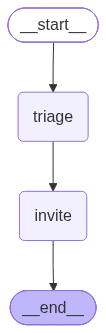

In [55]:
main_builder = StateGraph(MainState)
main_builder.add_node("triage", triage_subgraph)   # subgraph as a node
main_builder.add_node("invite", invite_subgraph)
main_builder.add_edge(START, "triage")
main_builder.add_edge("triage", "invite")
main_builder.add_edge("invite", END)

graph_a = main_builder.compile(checkpointer=checkpointer)  # your Postgres checkpointer
display(Image(graph_a.get_graph().draw_mermaid_png()))

In [56]:
RUN_B_THREAD_ID = str(uuid.uuid4())
config = {"configurable": {"thread_id": RUN_B_THREAD_ID}}

# Leave customer_ids empty to scan every non-terminal tracking row, or pass
# specific customer_ids to limit this run to a subset (e.g. your own test
# inbox's customer_id). Unlike Run A's demo, nothing here is simulated --
# no node has an interrupt(), so this really reads Gmail replies and really
# creates + sends a Calendly scheduling link for anyone now 'interested'.
# This graph stops there -- checking for an actual booking and notifying
# Slack is a separate, later graph. Only run against a live DATABASE_URL
# with rows you're prepared to have emailed.
result = await graph_a.ainvoke({"customer_ids": []}, config)

print("triaged:", result["triaged"])
print("invited:", result["invited"])
if result.get("errors"):
    print("errors:", result["errors"])

triaged: [{'customer_id': 402, 'decision': 'NEEDED'}]
invited: [{'customer_id': 402, 'scheduling_link': 'https://calendly.com/d/dvpy-td5-6df'}]
